# 04 – Zeitbasierte Modell-Baseline

Die Baseline beantwortet die Frage: **Steigt der Schlusskurs am nächsten Handelstag?** Verwendet wird eine nachvollziehbare logistische Regression. Der Split erfolgt chronologisch, damit keine zukünftigen Daten in das Training gelangen.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.model_baseline import load_model_data, train_baseline

pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sheo1\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


## Training und zeitlicher Holdout

Die ältesten 80 % der Handelstage bilden das Training; die jüngsten 20 % bleiben als realitätsnähere Testperiode vollständig unbekannt.

In [2]:
model_data = load_model_data()
model, metrics, predictions = train_baseline(model_data, save_artifacts=False)

metric_table = pd.DataFrame({
    'Kennzahl': ['Mehrheitsbaseline Accuracy', 'Modell Accuracy', 'Balanced Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Wert': [
        metrics['majority_baseline_accuracy'], metrics['accuracy'],
        metrics['balanced_accuracy'], metrics['precision'], metrics['recall'],
        metrics['f1'], metrics['roc_auc'],
    ],
})
metric_table['Wert'] = metric_table['Wert'].round(4)
print(f"Training: {metrics['train_start']} bis {metrics['train_end']} ({metrics['train_rows']} Zeilen)")
print(f"Test:     {metrics['test_start']} bis {metrics['test_end']} ({metrics['test_rows']} Zeilen)")
metric_table

Training: 2021-10-06 bis 2025-08-29 (4923 Zeilen)
Test:     2025-09-01 bis 2026-08-24 (1233 Zeilen)


,Kennzahl,Wert
0,Mehrheitsbaseline Accuracy,0.5337
1,Modell Accuracy,0.5191
2,Balanced Accuracy,0.4929
3,Precision,0.5297
4,Recall,0.8815
5,F1,0.6617
6,ROC-AUC,0.5278


## Fehlertypen

Die Konfusionsmatrix zeigt nicht nur die Gesamtquote, sondern ob das Modell eine Richtung systematisch bevorzugt.

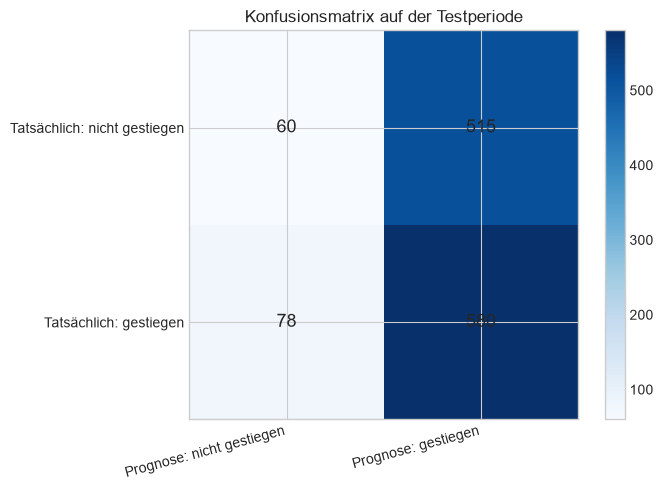

,Prognose: nicht gestiegen,Prognose: gestiegen
Tatsächlich: nicht gestiegen,60,515
Tatsächlich: gestiegen,78,580


In [3]:
matrix = pd.DataFrame(
    metrics['confusion_matrix'],
    index=['Tatsächlich: nicht gestiegen', 'Tatsächlich: gestiegen'],
    columns=['Prognose: nicht gestiegen', 'Prognose: gestiegen'],
)
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(matrix, cmap='Blues')
ax.set_xticks(range(2), matrix.columns, rotation=15, ha='right')
ax.set_yticks(range(2), matrix.index)
for row in range(2):
    for column in range(2):
        ax.text(column, row, matrix.iloc[row, column], ha='center', va='center', fontsize=13)
fig.colorbar(image, ax=ax)
ax.set_title('Konfusionsmatrix auf der Testperiode')
plt.tight_layout()
plt.show()
matrix

## Trennschärfe unabhängig vom Schwellenwert

Die ROC-Kurve bewertet die Rangordnung der Wahrscheinlichkeiten. Eine AUC von 0,5 entspricht Zufallsniveau.

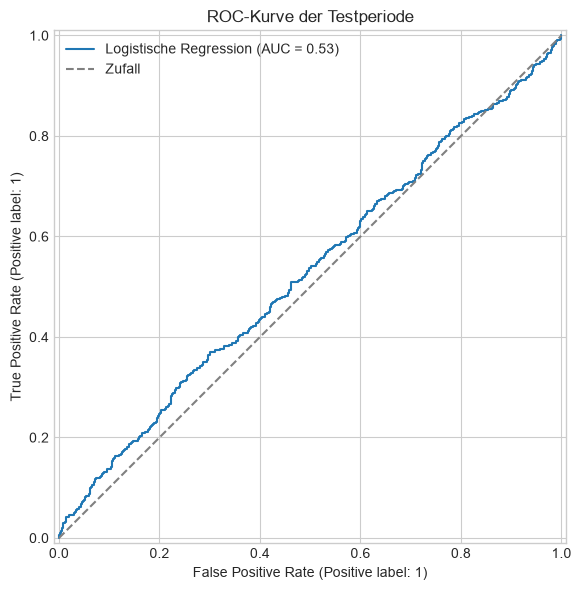

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    predictions['actual'], predictions['probability_up'], ax=ax, name='Logistische Regression'
)
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Zufall')
ax.set_title('ROC-Kurve der Testperiode')
ax.legend()
plt.tight_layout()
plt.show()

## Einfluss der Modellmerkmale

Die Koeffizienten dienen der technischen Interpretierbarkeit. Sie sind keine kausalen Aussagen und keine Anlageempfehlung.

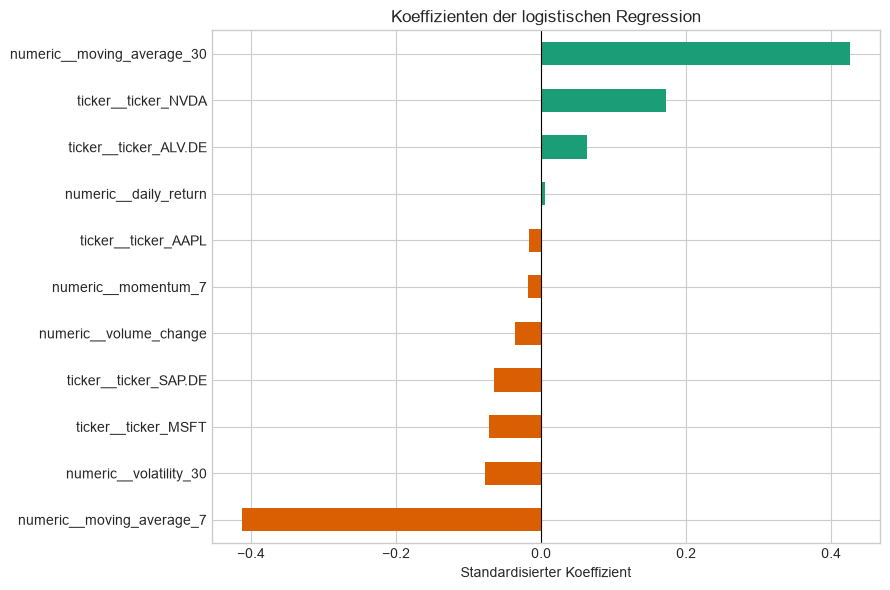

In [5]:
feature_names = model.named_steps['preprocessing'].get_feature_names_out()
coefficients = (pd.Series(model.named_steps['classifier'].coef_[0], index=feature_names)
                .sort_values())
colors = ['#d95f02' if value < 0 else '#1b9e77' for value in coefficients]
ax = coefficients.plot(kind='barh', figsize=(9, 6), color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Koeffizienten der logistischen Regression', xlabel='Standardisierter Koeffizient', ylabel='')
plt.tight_layout()
plt.show()

## Einordnung

Die Baseline demonstriert die vollständige ML-Bereitstellung, liefert aber bewusst keinen Nachweis verlässlicher Überrenditen. Entscheidend für den Proof of Concept sind der leakage-freie Zeit-Split, reproduzierbare Kennzahlen und die klare Trennung von Daten- und Modellschicht.